# Building an agent: code and architecture

This notebook walks through **how an agent is put together**: what the runner
hands you each hour, what you must hand back, how a bid vector is built and
how it clears, and how the pieces become one submission file. It is about the
plumbing, not about strategy. Every price used below (80% of the grid price,
1¢, …) is a placeholder chosen to be easy to read, not a recommendation.

| part | what you learn | needs the course dataset? |
|---|---|---|
| 1. The hour loop | who calls what, in which order, and what you never see | no |
| 2. What you are handed | `BuildingObs` and `MarketInfo`, field by field | no |
| 3. Bid vectors | the array format, the `Bid` helper, curves with several steps | no |
| 4. How a bid clears | running the market yourself, reading the result | no |
| 5. Writing an agent | `reset` / `bid` / `dispatch`, planning once, portfolios, subclassing the default agent | no |
| 6. A test bench | running agents for two days on a fake neighbourhood, reading the ledger, what the runner does with mistakes | no |
| 7. From notebook to submission | the file format, loading it the way the runner does, one run in the real course market | the last cell only |

**Running it.** From the repository root, after the setup in the
[README](../README.md#getting-set-up):

```bash
python -m pip install jupyterlab      # once, if you do not have Jupyter
jupyter lab docs/building_an_agent.ipynb
```

Run the cells from the top. Parts 1–6 run in seconds and need nothing but
this repository; the last cell of part 7 runs your agent for two days in the
real course market and is skipped if `generated/altered_stock/` has not been
built.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# The notebook lives in docs/; find the repository root either way.
ROOT = Path.cwd() if (Path.cwd() / "src" / "annex96p2p").exists() else Path.cwd().parent
assert (ROOT / "src" / "annex96p2p").exists(), "run this notebook from the repository"

import annex96p2p
from annex96p2p import Action, Agent, Bid, BuildingObs, MarketInfo, Thermostat, TradeResult
from annex96p2p.market import build_price_grid, clear, validate_bid

pd.set_option("display.width", 140)
package = Path(annex96p2p.__file__).resolve().parent
print("annex96p2p imported from",
      package.relative_to(ROOT.resolve()) if ROOT.resolve() in package.parents else package)

annex96p2p imported from src\annex96p2p


## 1. The hour loop

A run is a loop over hours. Each hour, the runner
([`runner.py`](../src/annex96p2p/runner.py), function `simulate`) does six
things, always in this order:

```
            ┌──────────────────────────── one hour ─────────────────────────────┐
 backend ─► │ 1 observe   every building's state at the start of the hour        │
            │ 2 bid       YOUR agent.bid(obs, mkt)        → one bid vector       │
 market  ─► │ 3 clear     all bid vectors at once         → one price, quantities│
            │ 4 dispatch  YOUR agent.dispatch(obs, mkt, result) → Actions        │
 backend ─► │ 5 physics   heat pumps, batteries, PV for one hour                 │
 ledger  ─► │ 6 settle    market trades at the clearing price, the rest with the │
            │             grid; comfort penalty; one row per participant         │
            └────────────────────────────────────────────────────────────────────┘
```

You write steps 2 and 4. Everything else is fixed. Three consequences shape
every agent:

- **You bid before you act.** `bid()` has to say what you will consume or
  produce *before* `dispatch()` decides it. If the two disagree, the grid
  makes up the difference at full price, or the surplus is curtailed.
- **You act knowing your trade.** `dispatch()` receives a `TradeResult`: the
  price you cleared at and how much you bought or sold.
- **You see only your own buildings.** `obs` contains your buildings and
  nothing else; `mkt` is the same public information for everyone. You never
  see anyone else's bids, loads or trades — only last hour's clearing price
  and volume.

The contract is the abstract base class `Agent`:

In [2]:
import inspect

for method in ("reset", "bid", "dispatch"):
    sig = inspect.signature(getattr(Agent, method))
    doc = inspect.getdoc(getattr(Agent, method)).splitlines()[0]
    print("%-9s%-38s %s" % (method, str(sig), doc))

reset    (self) -> 'None'                       Optional hook, called once before the simulation starts.
bid      (self, obs: 'Dict[str, BuildingObs]', mkt: 'MarketInfo') -> 'np.ndarray' Return a bid vector of length `mkt.n_levels`.
dispatch (self, obs: 'Dict[str, BuildingObs]', mkt: 'MarketInfo', result: 'TradeResult') -> 'Dict[str, Action]' Return one Action per building you control, keyed by building name.


**Sign conventions**, the same everywhere in the package:

| quantity | positive | negative |
|---|---|---|
| energy (`net_kwh`, `passive_net_kwh`, …) | you consume / need to buy | you produce / have surplus |
| a bid vector entry | **buy** that many kWh at that price | **sell** that many kWh at that price |
| `TradeResult.quantity` | you bought from peers | you sold to peers |
| `Action.hvac` | heating | cooling |
| `Action.battery` | charge | discharge |

## 2. What you are handed

### `obs`: one `BuildingObs` per building you control

`obs` is a dict keyed by building name. Normally the runner builds these
from the simulator; here we build two by hand so you can look at them. The
numbers are made up but shaped like the course houses: a PV-rich home (40 kW
of PV, a 4 kWh / 1 kW battery) and a storage-rich home (1 kW of PV, an
80 kWh / 80 kW battery), at 13:00 on a January day.

In [3]:
pv_home = BuildingObs(
    name="resstock-amy2018-2021-release-1-112208", timestep=13, hour=13, day=0,
    outdoor_temperature=-4.0, solar_irradiance=0.6,
    indoor_temperature=19.6, comfort_low=18.0, comfort_high=22.0,
    base_load_kwh=1.2, solar_generation_kwh=14.5,
    battery_soc_kwh=2.0, battery_capacity_kwh=4.0, battery_max_power_kw=1.0,
    hp_max_electric_kw=6.0, hp_cop=2.4, hp_is_heating=True, last_net_kwh=-9.8,
)
storage_home = BuildingObs(
    name="resstock-amy2018-2021-release-1-199613", timestep=13, hour=13, day=0,
    outdoor_temperature=-4.0, solar_irradiance=0.6,
    indoor_temperature=20.4, comfort_low=19.0, comfort_high=23.0,
    base_load_kwh=0.9, solar_generation_kwh=0.4,
    battery_soc_kwh=30.0, battery_capacity_kwh=80.0, battery_max_power_kw=80.0,
    hp_max_electric_kw=8.0, hp_cop=2.4, hp_is_heating=True, last_net_kwh=1.1,
)
obs = {o.name: o for o in (pv_home, storage_home)}

pd.DataFrame([vars(o) for o in obs.values()]).set_index("name").T

name,resstock-amy2018-2021-release-1-112208,resstock-amy2018-2021-release-1-199613
timestep,13,13
hour,13,13
day,0,0
outdoor_temperature,-4.0,-4.0
solar_irradiance,0.6,0.6
indoor_temperature,19.6,20.4
comfort_low,18.0,19.0
comfort_high,22.0,23.0
base_load_kwh,1.2,0.9
solar_generation_kwh,14.5,0.4


Everything is **this hour**: `base_load_kwh` and `solar_generation_kwh` are
the energy for the hour about to happen, `battery_soc_kwh` is the charge
right now. One caveat specific to the course dataset: the simulator's
observations run one hour ahead of its physics, so the PV you observe is not
exactly the PV you will produce (README, "Writing a submission").

A few helpers do the arithmetic you would otherwise get wrong:

In [4]:
for o in obs.values():
    print(o.name[-6:],
          "| passive net %+6.2f kWh" % o.passive_net_kwh,     # load - PV, heat pump and battery idle
          "| comfort mid %.1f °C" % o.comfort_mid,
          "| battery %s, PV %s" % (o.has_battery, o.has_pv))

112208 | passive net -13.30 kWh | comfort mid 20.0 °C | battery True, PV True
199613 | passive net  +0.50 kWh | comfort mid 21.0 °C | battery True, PV True


`passive_net_kwh` is the starting point of every bid: what the building would
draw (positive) or spill (negative) if the heat pump and battery did nothing.
The PV home has a 13 kWh surplus; the storage home needs 0.5 kWh.

**The heat pump is a fraction of rated power, and only one sign works.**
`Action.hvac` runs from −1 (full cooling) to +1 (full heating), but each
building has a heat pump plumbed one way only. On these heating-only homes a
negative command is simply off. `hp_draw_kwh()` gives the electricity a
command actually draws:

In [5]:
for hvac in (1.0, 0.4, 0.0, -0.5):
    naive = abs(hvac) * pv_home.hp_max_electric_kw
    print("hvac %+.1f   draws %.1f kWh   (abs(hvac) * max would say %.1f)"
          % (hvac, pv_home.hp_draw_kwh(hvac), naive))

hvac +1.0   draws 6.0 kWh   (abs(hvac) * max would say 6.0)
hvac +0.4   draws 2.4 kWh   (abs(hvac) * max would say 2.4)
hvac +0.0   draws 0.0 kWh   (abs(hvac) * max would say 0.0)
hvac -0.5   draws 0.0 kWh   (abs(hvac) * max would say 3.0)


### `mkt`: one `MarketInfo`, the same for everyone

It carries the clock, the grid price and **the legal price grid**: the price
levels you may bid at, from $0.00 to the grid price in one-cent steps. The
grid price is the ceiling because anyone can buy from the grid at that
price; the floor is zero because unsold surplus cannot be exported and earns
nothing.

In [6]:
mkt = MarketInfo(
    timestep=13, hour=13, day=0,
    grid_import_price=0.20, grid_export_price=0.0,
    price_grid=build_price_grid(0.20),          # what the runner uses
    last_clearing_price=0.07, last_clearing_volume=310.0,
)
print("levels:", mkt.n_levels)
print("prices:", mkt.price_grid[:4], "...", mkt.price_grid[-3:])
print("level index of $0.137:", mkt.level(0.137), "->", mkt.price_grid[mkt.level(0.137)])
print("level index of $0.95 :", mkt.level(0.95), "-> clipped to the grid price",
      mkt.price_grid[mkt.level(0.95)])

levels: 21
prices: [0.   0.01 0.02 0.03] ... [0.18 0.19 0.2 ]
level index of $0.137: 14 -> 0.14
level index of $0.95 : 20 -> clipped to the grid price 0.2


The grid price changes every hour, so **the number of levels changes every
hour too**: always size your bid from `mkt`, never from a constant.

In [7]:
for price in (0.055, 0.20, 0.45):
    print("grid price $%.3f -> %d levels, top level $%.2f"
          % (price, len(build_price_grid(price)), build_price_grid(price)[-1]))

grid price $0.055 -> 6 levels, top level $0.05
grid price $0.200 -> 21 levels, top level $0.20
grid price $0.450 -> 46 levels, top level $0.45


## 3. Bid vectors

### The raw format

`bid()` returns a numpy array with **one signed number per price level**,
`len(mkt.price_grid)` long. Entry *k* is how much you would trade at price
`mkt.price_grid[k]`:

- **positive** at level *k*: *buy up to that many kWh at that price or cheaper*;
- **negative** at level *k*: *sell up to that many kWh at that price or dearer*;
- zero: nothing at that level.

So one entry is a limit order. The simplest bid of all is the empty one:

In [8]:
bid = mkt.empty_bid()             # zeros, the right length for this hour
bid[mkt.level(0.06)] = +4.0       # buy up to 4 kWh, paying at most $0.06
bid[mkt.level(0.16)] = -2.0       # sell up to 2 kWh, accepting at least $0.16
print(len(bid), "levels;", "nonzero:", {float(mkt.price_grid[k]): float(bid[k]) for k in np.flatnonzero(bid)})

21 levels; nonzero: {0.06: 4.0, 0.16: -2.0}


### The `Bid` helper

Indexing by hand is error-prone. `mkt.new_bid()` returns a `Bid` that snaps
prices to the nearest level, accumulates quantities and prints readably. Its
`.array` is the vector you return. Below, `describe()` prints any vector the same way.

In [9]:
b = mkt.new_bid()
b.buy(price=0.06, quantity=4.0)
b.sell(price=0.16, quantity=2.0)
print(b)
print("same vector as above:", np.array_equal(b.array, bid))


def describe(vector):
    # Readable form of any bid vector (what Bid prints), for this hour's mkt.
    b = mkt.new_bid()
    b.array = np.asarray(vector, dtype=float)
    return repr(b)

print(describe(bid))

Bid(buy 4.00 kWh @ $0.06; sell 2.00 kWh @ $0.16)
same vector as above: True
Bid(buy 4.00 kWh @ $0.06; sell 2.00 kWh @ $0.16)


Three details of the helper:

In [10]:
b = mkt.new_bid()
b.buy(price=0.1649, quantity=1.0)          # snaps to the nearest level, $0.16
b.buy(price=0.16, quantity=2.0)            # same level: quantities add up
print(b)

b = mkt.new_bid()
b.buy(price=0.08, quantity=3.0).sell(price=0.08, quantity=1.0)   # calls chain
print(b, "  <- one number per level: buy 3 and sell 1 at $0.08 net to buy 2")

b = mkt.new_bid()
b.buy(price=0.10, quantity=-5.0)           # non-positive quantities are ignored
print(b)

Bid(buy 3.00 kWh @ $0.16)
Bid(buy 2.00 kWh @ $0.08)   <- one number per level: buy 3 and sell 1 at $0.08 net to buy 2
Bid(empty)


### A curve with several steps

Because each level is its own limit order, putting quantities at several
levels builds a **curve**: how much you want at every price. Here a buyer
wants 2 kWh whatever happens (the heat pump will run anyway), and 3 kWh more
only if it is cheap (say, to charge a battery):

In [11]:
b = mkt.new_bid()
b.buy(price=0.19, quantity=2.0)     # must-have energy: pay up to just under the grid price
b.buy(price=0.06, quantity=3.0)     # nice-to-have: only if it is cheap
print(b)

# What the market reads from it: at price p you buy everything bid at p or above.
willing = np.cumsum(np.clip(b.array, 0, None)[::-1])[::-1]
for p in (0.03, 0.06, 0.07, 0.15, 0.19, 0.20):
    print("  if the market clears at $%.2f you would buy %.0f kWh" % (p, willing[mkt.level(p)]))

Bid(buy 3.00 kWh @ $0.06; buy 2.00 kWh @ $0.19)
  if the market clears at $0.03 you would buy 5 kWh
  if the market clears at $0.06 you would buy 5 kWh
  if the market clears at $0.07 you would buy 2 kWh
  if the market clears at $0.15 you would buy 2 kWh
  if the market clears at $0.19 you would buy 2 kWh
  if the market clears at $0.20 you would buy 0 kWh


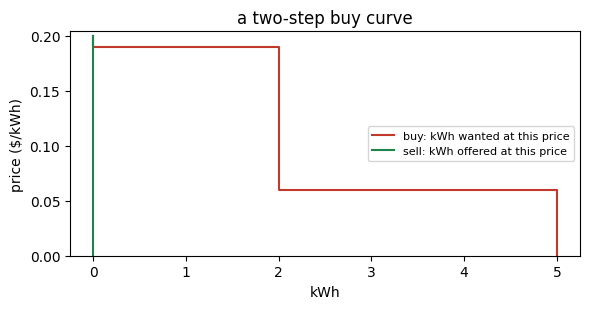

In [12]:
import matplotlib.pyplot as plt

def plot_curve(b, mkt, title):
    buy = np.cumsum(np.clip(b.array, 0, None)[::-1])[::-1]
    sell = np.cumsum(np.clip(-b.array, 0, None))
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.step(buy, mkt.price_grid, where="post", color="#c0392b", label="buy: kWh wanted at this price")
    ax.step(sell, mkt.price_grid, where="post", color="#1e8449", label="sell: kWh offered at this price")
    ax.set_xlabel("kWh"); ax.set_ylabel("price ($/kWh)"); ax.set_title(title)
    ax.set_ylim(0, mkt.grid_import_price * 1.02); ax.legend(loc="center right", fontsize=8)
    fig.tight_layout()

b = mkt.new_bid().buy(0.19, 2.0).buy(0.06, 3.0)
plot_curve(b, mkt, "a two-step buy curve")

### One bid, two pictures

Selling works the same way, and one bid may buy *and* sell, at different
prices. Here is a storage-rich home at the 18:00 peak, when the grid charges
40¢. Its plan depends on the price:

- **cheap (up to 8¢):** buy 8 kWh, its own 2 kWh load plus 6 kWh to charge
  the battery;
- **moderate (up to 24¢):** buy just the 2 kWh for its load;
- **good (from 25¢):** stop buying, run the house from the battery, and sell
  the 1 kWh it can spare;
- **very good (from 34¢):** sell 5 kWh more.

Every buy is below every sell, so the four steps never overlap. One vector:

In [13]:
evening = MarketInfo(timestep=18, hour=18, day=0, grid_import_price=0.40, grid_export_price=0.0,
                     price_grid=build_price_grid(0.40), last_clearing_price=0.31,
                     last_clearing_volume=420.0)

store = evening.new_bid()
store.buy(0.08, 6.0)      # charge the battery, only if energy is cheap
store.buy(0.24, 2.0)      # its own load, up to 24¢; above that the battery covers it
store.sell(0.25, 1.0)     # from 25¢: sell the 1 kWh it can spare ...
store.sell(0.34, 5.0)     # ... and from 34¢, 5 kWh more
print(store)

Bid(buy 6.00 kWh @ $0.08; buy 2.00 kWh @ $0.24; sell 1.00 kWh @ $0.25; sell 5.00 kWh @ $0.34)


**A bid does not have to be continuous.** You put a quantity only at each
order's *limit* price, and leave every other level at zero. The market then
extends each order itself:

- a **buy** counts at its limit **and every lower price** (if you would pay
  24¢, you would also pay 10¢);
- a **sell** counts at its limit **and every higher price** (if you would
  accept 25¢, you would also accept 30¢).

The figure shows both. On the left, each order is solid at its limit, the
one level you set in the vector, and faded at every level where it still
counts. Orders on the same side stack, so the width at a price is everything
that counts there. On the right is the net of the two sides: what the bid
**commits you to** at each price the market might clear at.

clears at  5¢ -> +8 kWh
clears at 20¢ -> +2 kWh
clears at 30¢ -> -1 kWh
clears at 36¢ -> -6 kWh


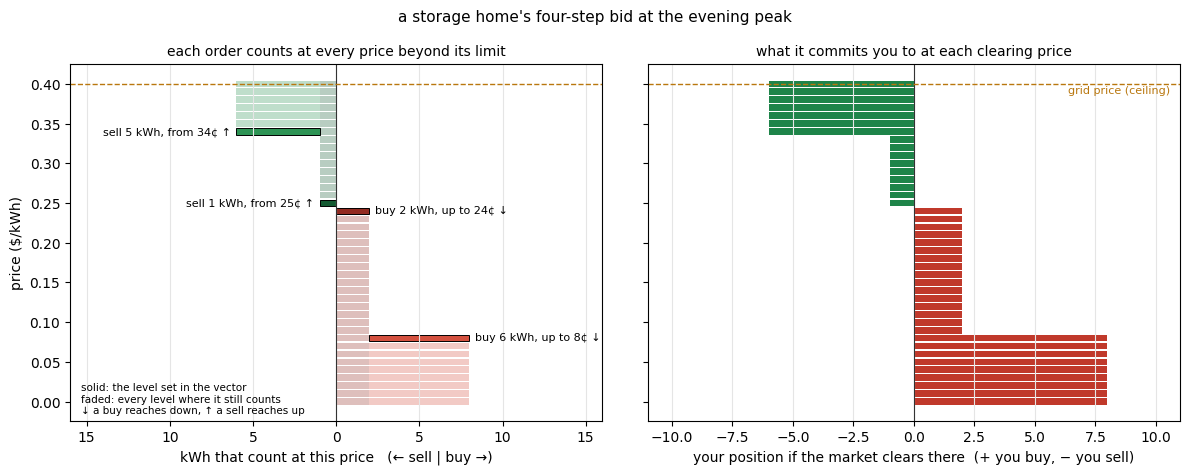

In [14]:
RED, GREEN, GREY = "#c0392b", "#1e8449", "#7f8c8d"
H = 0.0085                       # bar height: one price level, with a gap

def net_position(vector):
    # kWh you would end up with at each level's price: + buying, - selling.
    buy = np.cumsum(np.clip(vector, 0, None)[::-1])[::-1]     # bid to buy at this price or above
    sell = np.cumsum(np.clip(-vector, 0, None))               # offered at this price or below
    return buy - sell

BUY_SHADES = ["#922b21", "#d4513f", "#e88e7d", "#b03a2e", "#f0b3a6"]
SELL_SHADES = ["#145a32", "#2e9455", "#7cc08f", "#1d6e3e", "#b2dbbd"]

def orders_of(vector, prices, who=""):
    # Every nonzero level of a bid vector is one limit order.
    return [dict(who=who, k=int(k), price=float(prices[k]), qty=abs(float(vector[k])), buy=vector[k] > 0)
            for k in np.flatnonzero(vector)]

def draw_orders(ax, orders, prices, fontsize=8):
    # Stack each order over every level where it counts: a buy at its limit and
    # every lower price (drawn to the right), a sell at its limit and every
    # higher price (drawn to the left). Solid = the limit, faded = the reach.
    levels = np.arange(len(prices))
    buys = sorted((o for o in orders if o["buy"]), key=lambda o: -o["price"])
    sells = sorted((o for o in orders if not o["buy"]), key=lambda o: o["price"])
    for group, shades, sign in ((buys, BUY_SHADES, 1), (sells, SELL_SHADES, -1)):
        offset = np.zeros(len(prices))
        for i, o in enumerate(group):
            reach = levels <= o["k"] if o["buy"] else levels >= o["k"]
            colour = shades[i % len(shades)]
            ax.barh(prices[reach], sign * o["qty"], left=sign * offset[reach], height=H,
                    color=colour, alpha=0.3, lw=0)
            ax.barh([o["price"]], [sign * o["qty"]], left=[sign * offset[o["k"]]], height=H,
                    color=colour, edgecolor="black", lw=0.7)
            text = ("%s%s %.0f kWh, %s %.0f¢ %s" % (o["who"] + ": " if o["who"] else "",
                    "buy" if o["buy"] else "sell", o["qty"], "up to" if o["buy"] else "from",
                    100 * o["price"], "↓" if o["buy"] else "↑"))
            end = sign * (offset[o["k"]] + o["qty"])
            ax.annotate(text, (end, o["price"]), xytext=(4 * sign, 0), textcoords="offset points",
                        ha="left" if sign > 0 else "right", va="center", fontsize=fontsize)
            offset[reach] += o["qty"]
    ax.axvline(0, color="#333", lw=0.8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: "%g" % abs(x)))

def plot_bid(b, market, title):
    v, prices = b.array, market.price_grid
    net = net_position(v)
    fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
    draw_orders(left, orders_of(v, prices), prices)
    left.set_title("each order counts at every price beyond its limit", fontsize=10)
    left.set_xlabel("kWh that count at this price   (← sell | buy →)")
    left.set_xlim(-16, 16)
    left.text(0.02, 0.02, "solid: the level set in the vector\nfaded: every level where it still counts\n"
              "↓ a buy reaches down, ↑ a sell reaches up", transform=left.transAxes, fontsize=7.5)
    right.barh(prices, net, height=H, color=np.where(net > 0, RED, np.where(net < 0, GREEN, GREY)))
    right.set_title("what it commits you to at each clearing price", fontsize=10)
    right.set_xlabel("your position if the market clears there  (+ you buy, − you sell)")
    right.set_xlim(-11, 11)
    right.axvline(0, color="#333", lw=0.8)
    for ax in (left, right):
        ax.axhline(market.grid_import_price, color="#b9770e", ls="--", lw=1)
        ax.grid(axis="x", color="#e5e5e5")
    left.set_ylabel("price ($/kWh)")
    right.text(10.6, market.grid_import_price - 0.012, "grid price (ceiling)", color="#b9770e",
               fontsize=8, ha="right")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()

plot_bid(store, evening, "a storage home's four-step bid at the evening peak")

for p in (0.05, 0.20, 0.30, 0.36):
    print("clears at %2.0f¢ -> %+.0f kWh" % (100 * p, net_position(store.array)[evening.level(p)]))

Read it from the bottom up. Up to 8¢ both buys count: 8 kWh. From 9¢ to 24¢
only the 24¢ buy still counts: 2 kWh. At 25¢ the buys have all dropped out
and the first sell starts: 1 kWh. From 34¢ both sells count: 6 kWh. Four
numbers in the vector define a position at every one of the 41 prices. The
market adds up these reaches over everyone, and the clearing price picks one
row.

A bid may also buy at a price above one of its own sells. The market
**nets** every bid before clearing, so only the right-hand picture counts:
the bid clears exactly like the non-overlapping bid with the same net
position. Keeping every buy below every sell, as here, simply means the
left-hand picture already reads as the plan. The cell below checks it with
an overlapping version of the same plan.

In [15]:
overlapping = evening.new_bid()
overlapping.buy(0.08, 6.0)
overlapping.buy(0.38, 2.0)      # its load bid almost to the grid price ...
overlapping.sell(0.25, 3.0)     # ... so the first sale has to be 2 kWh larger
overlapping.sell(0.34, 5.0)

same = np.allclose(net_position(overlapping.array)[:39], net_position(store.array)[:39])
print(overlapping)
print("same position as `store` up to 38¢:", same)
print("at 39-40¢ the 38¢ buy stops counting:", net_position(overlapping.array)[39:], "vs", net_position(store.array)[39:])

Bid(buy 6.00 kWh @ $0.08; sell 3.00 kWh @ $0.25; sell 5.00 kWh @ $0.34; buy 2.00 kWh @ $0.38)
same position as `store` up to 38¢: True
at 39-40¢ the 38¢ buy stops counting: [-8. -8.] vs [-6. -6.]


Up to 38¢ the two bids are the same position. At 39¢ and 40¢ they differ,
because the overlapping bid's load purchase stops at 38¢: there it sells
8 kWh net, `store` sells 6. Netting makes the market see exactly these
staircases, whichever way they were written.

### What the runner does with a malformed vector

Your vector goes through `validate_bid` before it reaches the market. A bad
bid never crashes the run; it is repaired, and the repair is written to the
run's warnings:

In [16]:
cases = {
    "too short":        np.ones(5),
    "NaN entries":      np.where(np.arange(mkt.n_levels) == 3, np.nan, 0.0),
    "absurd quantity":  np.where(np.arange(mkt.n_levels) == 3, 1e6, 0.0),
    "a Python list":    [0.0] * mkt.n_levels,
}
for label, raw in cases.items():
    fixed, notes = validate_bid(raw, mkt.n_levels, max_kwh=500.0, who="me")
    print("%-16s -> length %d, %s" % (label, len(fixed), notes or "accepted as is"))

too short        -> length 21, ['me: bid length 5, expected 21 -- padded/truncated']
NaN entries      -> length 21, ['me: 1 non-finite bid entries zeroed']
absurd quantity  -> length 21, ['me: 1 bid entries clipped to +/-500 kWh']
a Python list    -> length 21, accepted as is


Repaired is not the same as right: a padded vector bids zero at the levels it
was missing. Size every bid from `mkt`.

## 4. How a bid clears

The market is one function, `clear(bids, price_grid)` in
[`market.py`](../src/annex96p2p/market.py). You can call it directly, which
is the quickest way to check that a bid means what you think. Here our
two-step buyer meets two sellers:

In [17]:
me = mkt.new_bid().buy(0.19, 2.0).buy(0.06, 3.0)
solar = mkt.new_bid().sell(0.01, 4.0)          # a PV home spilling surplus
battery = mkt.new_bid().sell(0.12, 10.0)       # a storage home selling at 12¢

clearing = clear({"me": me.array, "solar": solar.array, "battery": battery.array},
                 mkt.price_grid)
print("price  :", clearing.price)
print("volume :", round(clearing.volume, 3), "kWh")
print("trades :", {k: round(v, 3) for k, v in clearing.quantities.items()})

price  : 0.04
volume : 4.0 kWh
trades : {'me': 4.0, 'solar': -4.0, 'battery': 0.0}


The rule (the README's "Bidding" section has it in full):

0. **Netting.** Each bid is first reduced to its net position at every
   price (the right-hand picture of part 3): a buyer or a seller there,
   never both.
1. **Most volume.** For every price *p*, demand is everything bid to buy at
   *p* or above, supply everything offered at *p* or below; the market picks
   the price that trades the most energy.
2. **Ties: closest to the crossing.** Bids are steps, so often a whole range
   of prices trades that same volume. The market then takes the one where
   demand and supply are closest, and the middle only if that still ties.
3. **One price for everyone.** Everyone in the money trades at the clearing
   price, whatever they bid. The short side is filled completely, the long
   side shares pro rata.

Above, 4 kWh of solar is offered from 1¢. Our 5 kWh of demand at 6¢ or less
is more than that, so the solar is the short side and sells out. The 12¢
battery is never needed. The clearing curves show why:

In [18]:
table = pd.DataFrame({"price": clearing.price_grid, "demand": clearing.demand_curve,
                      "supply": clearing.supply_curve})
table["traded"] = np.minimum(table.demand, table.supply)
table["gap"] = (table.demand - table.supply).abs()
table["cleared here"] = np.where(np.arange(len(table)) == clearing.level_index, "<==", "")
table[table.price.isin([0.0, 0.01, 0.03, 0.05, 0.06, 0.07, 0.11, 0.12, 0.19, 0.20])].round(2)

,price,demand,supply,traded,gap,cleared here
0,0.00,5.0,0.0,0.0,5.0,
1,0.01,5.0,4.0,4.0,1.0,
3,0.03,5.0,4.0,4.0,1.0,
5,0.05,5.0,4.0,4.0,1.0,
6,0.06,5.0,4.0,4.0,1.0,
7,0.07,2.0,4.0,2.0,2.0,
11,0.11,2.0,4.0,2.0,2.0,
12,0.12,2.0,14.0,2.0,12.0,
19,0.19,2.0,14.0,2.0,12.0,
20,0.20,0.0,14.0,0.0,14.0,


Every price from 1¢ to 6¢ trades the same 4 kWh. At those prices the gap
between demand and supply is the same 1 kWh, so the market takes the middle
of the range. What each participant learns is a `TradeResult`, the third
argument of `dispatch()`:

In [19]:
for name in ("me", "solar", "battery"):
    r = clearing.result_for(name)
    print("%-8s price %s, quantity %+.2f kWh, traded=%s" % (name, r.price, r.quantity, r.traded))

me       price 0.04, quantity +4.00 kWh, traded=True
solar    price 0.04, quantity -4.00 kWh, traded=True
battery  price 0.04, quantity +0.00 kWh, traded=False


Two things to notice:

- **You pay the clearing price, not your bid.** "me" bid up to 19¢ for the
  first 2 kWh and pays 4¢ for all four.
- **A bid is not an obligation.** Nothing forces you to consume what you
  bought or produce what you sold. The grid settles the difference: buy too
  much and the excess is curtailed (paid for, then lost); sell too much and
  the shortfall is bought from the grid at full price. That is why bid and
  dispatch have to agree, which is what part 5 is about.

### A market clearing, as a picture

Three participants make a short table. With more participants and bids with
several steps, a picture is easier. Five participants at a 30¢ hour: a PV
home spilling 3 kWh, a storage home selling in two steps, two houses buying
(one in two steps), and a storage home that would charge only if energy is
very cheap.

In [20]:
peak = MarketInfo(timestep=17, hour=17, day=0, grid_import_price=0.30, grid_export_price=0.0,
                  price_grid=build_price_grid(0.30), last_clearing_price=0.21,
                  last_clearing_volume=380.0)

bids = {
    "PV home A":    peak.new_bid().sell(0.01, 3.0),
    "storage B":    peak.new_bid().sell(0.12, 6.0).sell(0.20, 6.0),
    "house C":      peak.new_bid().buy(0.29, 4.0).buy(0.15, 3.0),
    "house D":      peak.new_bid().buy(0.25, 5.0),
    "storage E":    peak.new_bid().buy(0.05, 8.0),
}
for name, b in bids.items():
    print("%-10s %s" % (name, b))

PV home A  Bid(sell 3.00 kWh @ $0.01)
storage B  Bid(sell 6.00 kWh @ $0.12; sell 6.00 kWh @ $0.20)
house C    Bid(buy 3.00 kWh @ $0.15; buy 4.00 kWh @ $0.29)
house D    Bid(buy 5.00 kWh @ $0.25)
storage E  Bid(buy 8.00 kWh @ $0.05)


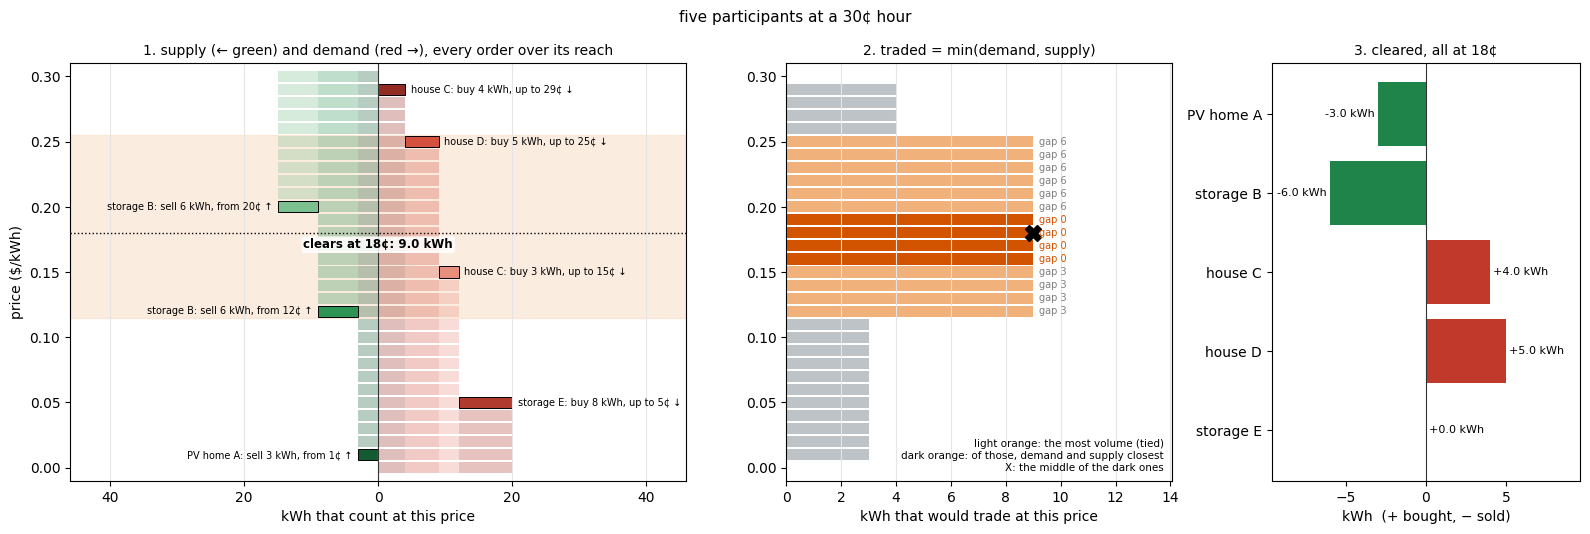

In [21]:
def plot_clearing(bids, market, title):
    c = clear({n: b.array for n, b in bids.items()}, market.price_grid)
    prices, D, S = c.price_grid, c.demand_curve, c.supply_curve
    traded = np.minimum(D, S)
    best = traded.max()
    tied = traded >= best - 1e-9
    gap = np.abs(D - S)
    closest = tied & (gap <= gap[tied].min() + 1e-9)

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.6, 1, 0.8]})

    # 1. Every order over its reach: supply stacks to the left, demand to the right.
    orders = [o for n, b in bids.items() for o in orders_of(b.array, prices, n)]
    draw_orders(ax1, orders, prices, fontsize=7)
    ax1.axhspan(prices[tied].min() - 0.005, prices[tied].max() + 0.005, color="#f5cba7", alpha=0.35, zorder=0)
    if c.price is not None:
        ax1.axhline(c.price, color="black", ls=":", lw=1)
        ax1.annotate("clears at %.0f¢: %.1f kWh" % (100 * c.price, c.volume), (0, c.price),
                     xytext=(0, -11), textcoords="offset points", ha="center", fontsize=8.5, weight="bold",
                     bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    lim = max(D.max(), S.max()) * 2.3
    ax1.set_xlim(-lim, lim)
    ax1.set_title("1. supply (← green) and demand (red →), every order over its reach", fontsize=10)
    ax1.set_xlabel("kWh that count at this price")
    ax1.set_ylabel("price ($/kWh)")

    # 2. Traded volume at every price: the market takes the most, then the smallest gap.
    colours = np.where(closest, "#d35400", np.where(tied, "#f0b27a", "#bdc3c7"))
    ax2.barh(prices, traded, height=H, color=colours)
    for k in np.flatnonzero(tied):
        ax2.text(traded[k] + 0.2, prices[k], "gap %.0f" % gap[k], va="center", fontsize=7,
                 color="#d35400" if closest[k] else "#7f7f7f")
    if c.price is not None:
        ax2.plot([c.volume], [c.price], "kX", ms=11)
    ax2.set_title("2. traded = min(demand, supply)", fontsize=10)
    ax2.set_xlabel("kWh that would trade at this price")
    ax2.set_xlim(0, best * 1.45 + 1)
    ax2.text(0.98, 0.02, "light orange: the most volume (tied)\n"
                          "dark orange: of those, demand and supply closest\n"
                          "X: the middle of the dark ones", transform=ax2.transAxes,
             ha="right", va="bottom", fontsize=7.5)

    # 3. Who got what.
    names = list(bids)
    q = np.array([c.quantities[n] for n in names])
    ax3.barh(names, q, color=np.where(q > 0, RED, np.where(q < 0, GREEN, GREY)))
    for i, v in enumerate(q):
        ax3.text(v + (0.2 if v >= 0 else -0.2), i, "%+.1f kWh" % v, va="center",
                 ha="left" if v >= 0 else "right", fontsize=8)
    ax3.axvline(0, color="#333", lw=0.8); ax3.invert_yaxis()
    lim = max(1.0, np.abs(q).max()) * 1.6
    ax3.set_xlim(-lim, lim)
    ax3.set_title("3. cleared, all at %s" % ("%.0f¢" % (100 * c.price) if c.price is not None else "no price"),
                  fontsize=10)
    ax3.set_xlabel("kWh  (+ bought, − sold)")

    for ax in (ax1, ax2):
        ax.set_ylim(-0.01, market.grid_import_price + 0.01)
        ax.grid(axis="x", color="#e5e5e5")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    return c

c = plot_clearing(bids, peak, "five participants at a 30¢ hour")

How to read it:

1. **Left.** Every order of every participant, solid at its limit and faded
   over its reach: buys reach down and stack to the right (demand), sells
   reach up and stack to the left (supply). The width of each side at a price
   is the total demand or supply there. At low prices many buy orders count
   but only the PV home sells; going up, buy orders drop out at their limits
   and sell orders join at theirs.
2. **Middle.** For each price, how much would actually trade: the smaller of
   demand and supply. Every price from 12¢ to 25¢ trades the same 9 kWh, the
   most possible (light orange). Within that range the gap between demand and
   supply is 3 kWh at 12–15¢, 0 at 16–19¢ and 6 at 20–25¢, so the market
   takes the smallest gap (dark orange) and, of those four prices, the middle:
   **18¢**.
3. **Right.** At 18¢ the PV home and storage B's first step sell 9 kWh; house
   C's must-have 4 kWh and house D's 5 kWh buy it. House C's second step
   (only up to 15¢), storage B's second step (only from 20¢) and storage E
   (only up to 5¢) are out of the money. Everyone who trades gets 18¢,
   including the PV home that asked 1¢.

`plot_clearing` takes any dict of bids, so change one and run it again. Here
the PV home has 5 kWh to sell instead of 3:

{'PV home A': -5.0, 'storage B': -6.0, 'house C': 6.42, 'house D': 4.58, 'storage E': 0.0}


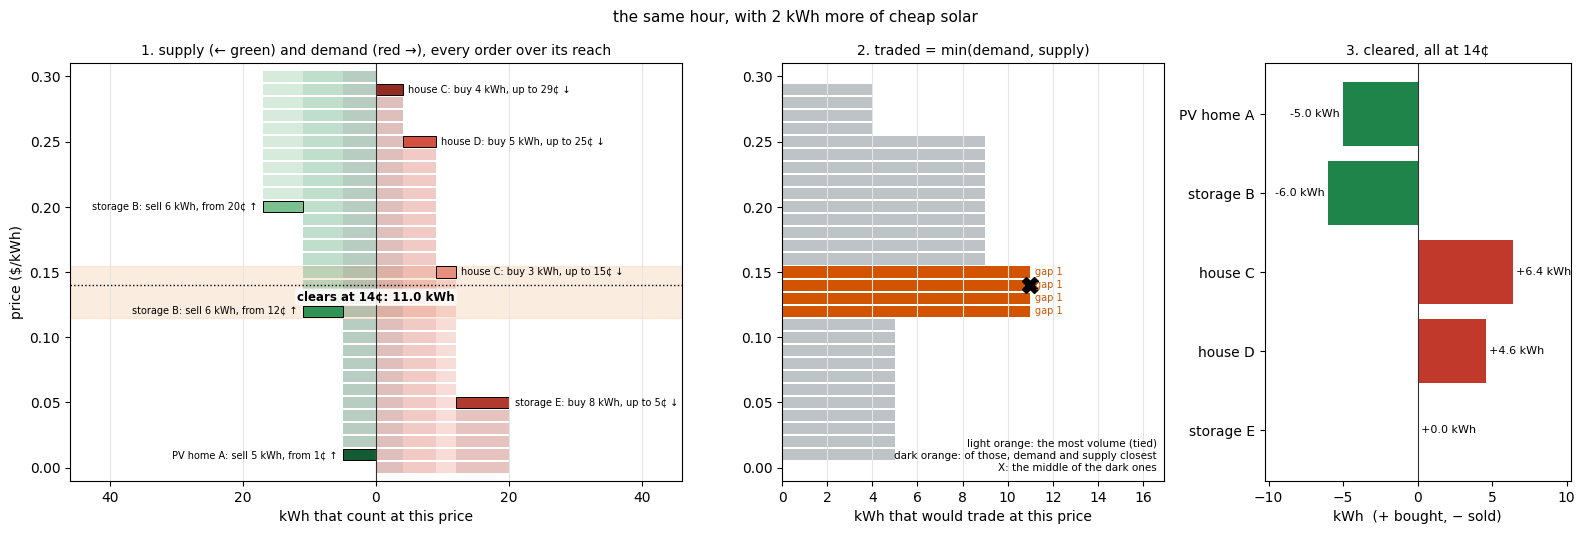

In [22]:
bids["PV home A"] = peak.new_bid().sell(0.01, 5.0)
c = plot_clearing(bids, peak, "the same hour, with 2 kWh more of cheap solar")
print({n: round(q, 2) for n, q in c.quantities.items()})

More supply moves the most-volume range down to 12–15¢, where 11 kWh can
trade, and the price falls to 14¢. Now demand is the long side: 12 kWh is bid
at that price (house C's second step is back in the money), and only 11 is
on offer, so the buyers share it pro rata: each gets 11/12 of what it bid.

## 5. Writing an agent

An agent is a subclass of `Agent` with three methods:

| method | called | receives | returns |
|---|---|---|---|
| `reset(self)` | once, before the first hour | — | nothing; set up your state here |
| `bid(self, obs, mkt)` | every hour, before clearing | your `obs`, `mkt` | a bid vector |
| `dispatch(self, obs, mkt, result)` | every hour, after clearing | the same `obs` and `mkt`, your `TradeResult` | `{building name: Action}` |

The runner constructs it as `AgentClass(name=..., buildings=[...])`, so
`self.name` and `self.buildings` are set for you. Do not override
`__init__`; put setup in `reset()`, which runs again at the start of every
run.

### Step 1: the smallest agent that runs

It never trades: an empty bid, and every building on the shared thermostat
with the battery idle. Everything it uses comes from the grid at full price.

In [23]:
class DoNothing(Agent):
    def reset(self):
        self.thermostat = Thermostat()

    def bid(self, obs, mkt):
        return mkt.empty_bid()

    def dispatch(self, obs, mkt, result):
        return {name: Action(hvac=self.thermostat(o), battery=0.0) for name, o in obs.items()}


agent = DoNothing(name="do_nothing", buildings=list(obs))
agent.reset()
print(agent.bid(obs, mkt).sum(), agent.dispatch(obs, mkt, TradeResult(price=None, quantity=0.0)))

0.0 {'resstock-amy2018-2021-release-1-112208': Action(hvac=0.0279999999999999, battery=0.0, net_target_kwh=None), 'resstock-amy2018-2021-release-1-199613': Action(hvac=0.0420000000000001, battery=0.0, net_target_kwh=None)}


`Action` has three fields:

| field | range | meaning |
|---|---|---|
| `hvac` | −1 … +1 | heat pump, as a **fraction** of rated power (+ heats) |
| `battery` | −1 … +1 | battery, as a **fraction** of rated power (+ charges) |
| `net_target_kwh` | kWh or `None` | optional: the grid exchange you want this hour; the battery then follows the load (step 4) |

`Thermostat` is the shared PI controller every agent may use. It holds the
middle of the comfort band, or wherever `aim` puts it (−1 bottom of the band,
+1 top). It has memory, and it is **idempotent within an hour**: calling it
again for the same building, hour and aim returns the same command instead
of advancing the controller twice.

In [24]:
t = Thermostat()
print(t(pv_home), t(pv_home), "  <- same hour, same answer")
print(t(pv_home, aim=-0.5), "  <- aim below the middle of the band")

0.0279999999999999 0.0279999999999999   <- same hour, same answer
-0.03600000000000012   <- aim below the middle of the band


### Step 2: bid what you need, and the classic bug

The obvious next step is to bid the passive position: buy what you lack, sell
what you have spare. This is the README's first example:

In [25]:
class PassiveBidder(Agent):
    BUY_AT, SELL_AT = 0.80, 0.20       # placeholder prices, as fractions of the grid price

    def reset(self):
        self.thermostat = Thermostat()

    def bid(self, obs, mkt):
        need = sum(o.passive_net_kwh for o in obs.values())
        b = mkt.new_bid()
        if need > 0:
            b.buy(self.BUY_AT * mkt.grid_import_price, need)
        else:
            b.sell(self.SELL_AT * mkt.grid_import_price, -need)
        return b.array

    def dispatch(self, obs, mkt, result):
        return {name: Action(hvac=self.thermostat(o), battery=0.0) for name, o in obs.items()}


agent = PassiveBidder("passive", list(obs)); agent.reset()
print(describe(agent.bid(obs, mkt)))
actions = agent.dispatch(obs, mkt, TradeResult(None, 0.0))
heat = sum(o.hp_draw_kwh(actions[n].hvac) for n, o in obs.items())
print("bid covers the passive position (%.2f kWh), but dispatch then runs the heat pumps: +%.2f kWh unbid"
      % (sum(o.passive_net_kwh for o in obs.values()), heat))

Bid(sell 12.80 kWh @ $0.04)
bid covers the passive position (-12.80 kWh), but dispatch then runs the heat pumps: +0.50 kWh unbid


It bids for load minus PV, then `dispatch()` switches the heat pumps on. That
energy was never bid for, so it comes from the grid at full price, or it
eats into surplus that was already sold. **Whatever you decide to do in
`dispatch()` has to be known in `bid()`.**

### Step 3: plan once, in `bid()`, and carry out the plan

The fix is a pattern, not a strategy: decide the heat pump and battery for
every building in `bid()`, bid exactly the energy that plan implies, store
the plan, and let `dispatch()` return it. This is what
[`agents/basic/half_battery.py`](../agents/basic/half_battery.py) does.

In [26]:
class Planner(Agent):
    BUY_AT, SELL_AT = 0.80, 0.20       # placeholders
    TARGET_SOC = 0.5                   # hold the battery half full

    def reset(self):
        self.thermostat = Thermostat()
        self.plan = {}                 # building -> Action, made in bid(), used in dispatch()

    def battery_step(self, o):
        # Battery command (-1..1) and the kWh it moves this hour.
        if not o.has_battery:
            return 0.0, 0.0
        gap = self.TARGET_SOC * o.battery_capacity_kwh - o.battery_soc_kwh
        kwh = max(-o.battery_max_power_kw, min(o.battery_max_power_kw, gap))
        return kwh / o.battery_max_power_kw, kwh    # one-hour steps: kW and kWh coincide

    def bid(self, obs, mkt):
        self.plan, net = {}, 0.0
        for name, o in obs.items():
            hvac = self.thermostat(o)
            battery, battery_kwh = self.battery_step(o)
            self.plan[name] = Action(hvac=hvac, battery=battery)
            net += o.passive_net_kwh + o.hp_draw_kwh(hvac) + battery_kwh
        b = mkt.new_bid()
        if net > 0:
            b.buy(self.BUY_AT * mkt.grid_import_price, net)
        elif net < 0:
            b.sell(self.SELL_AT * mkt.grid_import_price, -net)
        return b.array

    def dispatch(self, obs, mkt, result):
        return {name: self.plan.get(name, Action()) for name in obs}


agent = Planner("planner", list(obs)); agent.reset()
vector = agent.bid(obs, mkt)
print(describe(vector))
for name, a in agent.dispatch(obs, mkt, TradeResult(None, 0.0)).items():
    print(name[-6:], a)

Bid(sell 2.30 kWh @ $0.04)
112208 Action(hvac=0.0279999999999999, battery=0.0, net_target_kwh=None)
199613 Action(hvac=0.0420000000000001, battery=0.125, net_target_kwh=None)


The planned net energy is the sum, over buildings, of three terms:

```
passive_net_kwh          load − PV
+ hp_draw_kwh(hvac)      the heat pump command you are going to issue
+ battery kWh            + charging, − discharging
```

Two things this skeleton gets right that matter for any agent:

- **It nets the portfolio.** A participant with several buildings submits
  *one* bid. The PV home's surplus first covers the storage home's
  charging; only the remainder is offered. `obs` and the returned actions
  are both keyed by building name.
- **`hvac` and `battery` are fractions, the plan is in kWh.** The conversion
  happens in one place (`battery_step`, `hp_draw_kwh`), so bid and dispatch
  use the same numbers.

### Step 4: use what cleared

The plan above fixes the battery rate before the hour. `dispatch()` knows
more: `result` says what actually cleared. And `Action.net_target_kwh` lets
you say *how much you want to exchange with the outside* instead of a
battery rate. The battery then follows the load within the hour, like a home
inverter, absorbing forecast error instead of the grid. A minimal use: give
each building the grid exchange its plan implied.

In [27]:
class TargetPlanner(Planner):
    def bid(self, obs, mkt):
        vector = super().bid(obs, mkt)
        # Remember each building's planned exchange, in kWh.
        self.target = {}
        for name, o in obs.items():
            a = self.plan[name]
            _, battery_kwh = self.battery_step(o)
            self.target[name] = o.passive_net_kwh + o.hp_draw_kwh(a.hvac) + battery_kwh
        return vector

    def dispatch(self, obs, mkt, result):
        # result.quantity > 0: you bought that much; < 0: you sold it; 0: nothing cleared.
        return {name: Action(hvac=self.plan[name].hvac, net_target_kwh=self.target[name])
                for name in obs}


agent = TargetPlanner("target", list(obs)); agent.reset(); agent.bid(obs, mkt)
for name, a in agent.dispatch(obs, mkt, TradeResult(price=0.04, quantity=-11.0)).items():
    print(name[-6:], a)

112208 Action(hvac=0.0279999999999999, battery=0.0, net_target_kwh=-13.132000000000001)
199613 Action(hvac=0.0420000000000001, battery=0.0, net_target_kwh=10.836)


This version keeps the plan whatever cleared. Using `result` properly is
where strategy starts: if your sale did not clear, should the battery store
the surplus instead? The default agent splits the cleared quantity across
its houses in `dispatch()`; read it in
[`stock_agents.py`](../src/annex96p2p/stock_agents.py).

### Step 5: start from the default agent instead

Every unclaimed house runs `StorageServiceAgent`. It is built in the same
shape: `plan_hour(obs, mkt)` makes the plan and returns the portfolio's net
kWh, `bid()` prices it, and `dispatch()` carries the plan out using the
cleared quantity. So you can subclass it and replace only one part. Here
only the prices change; the physical plan stays exactly the default's:

In [28]:
from annex96p2p.stock_agents import StorageServiceAgent

class DefaultPlanMyPrices(StorageServiceAgent):
    def bid(self, obs, mkt):
        net = self.plan_hour(obs, mkt)          # the default's plan; fills self.plan
        b = mkt.new_bid()
        if net > 0:
            b.buy(mkt.grid_import_price, net)   # placeholder: pay up to the grid price
        elif net < 0:
            b.sell(0.5 * mkt.grid_import_price, -net)   # placeholder: sell from half of it
        return b.array
    # dispatch() is inherited: it delivers self.plan given result.quantity


agent = DefaultPlanMyPrices("mine", list(obs)); agent.reset()
vector = agent.bid(obs, mkt)
print(describe(vector))
print(agent.dispatch(obs, mkt, TradeResult(price=0.10, quantity=float(vector.sum()))))

Bid(sell 14.62 kWh @ $0.10)
{'resstock-amy2018-2021-release-1-112208': Action(hvac=0.0279999999999999, battery=0.0, net_target_kwh=-13.132000000000001), 'resstock-amy2018-2021-release-1-199613': Action(hvac=0.0420000000000001, battery=0.0, net_target_kwh=-1.4830036174568106)}


The methods you can override this way are `forecast` (expected net load
per house), `heat_command` (the heat pump), `topup` and `peak_need`
(when to fill the battery), `plan_hour`, `bid` and `dispatch`.
[`submissions/_template.py`](../submissions/_template.py) starts exactly
here, with nothing overridden.

## 6. A test bench: two days on a fake neighbourhood

To see an agent hour by hour you need a simulator. The full course market
needs the dataset and takes a minute; for checking **plumbing** there is a
tiny stand-in, `StubBackend` in [`tests/stub.py`](../tests/stub.py): six
buildings named `S01`–`S06`, batteries on the even ones and PV on the odd
ones, and no real physics at all.

> Use it to check that your code runs and that bid and dispatch agree. **Do
> not read anything into its bills.** Performance is only measured in the
> course market (part 7).

The runner's own `simulate()` takes a backend, a list of `Participant`s and
a `Tariff`. Our planner gets two buildings; the default agent runs the rest.

In [29]:
sys.path.insert(0, str(ROOT / "tests"))
from stub import StubBackend

from annex96p2p import Participant, Tariff, simulate

def run(agent_cls, mine=("S01", "S02"), days=2, **kwargs):
    # The stand-in keeps its rooms near 24 °C, so its thermostat mostly cools:
    # plumb the heat pumps for cooling to match.
    backend = StubBackend(n_buildings=6, days=days, hp_is_heating=False)
    participants = [Participant("me", agent_cls(name="me", buildings=list(mine)), list(mine))]
    participants += [Participant(b, StorageServiceAgent(name=b, buildings=[b]), [b], is_default=True)
                     for b in backend.building_names if b not in mine]
    tariff = Tariff.synthetic(backend.n_timesteps, comfort_price=0.50)
    return simulate(backend, participants, tariff, **kwargs)

result = run(Planner)
ledger = result.ledger.to_frame()
print("hours:", ledger.timestep.nunique(), "| ledger balances:", not result.ledger.check_balance())
ledger[ledger.participant == "me"].head(14)[
    ["timestep", "hour", "net_kwh", "p2p_kwh", "clearing_price", "grid_import_kwh",
     "curtailed_kwh", "p2p_cost", "grid_cost", "comfort_cost", "total_cost"]].round(3)

hours: 48 | ledger balances: True


,timestep,hour,net_kwh,p2p_kwh,clearing_price,grid_import_kwh,curtailed_kwh,p2p_cost,grid_cost,comfort_cost,total_cost
0,0,0,3.800,0.000,NaN,3.800,0.0,0.000,0.369,0.0,0.369
5,1,1,4.032,0.000,NaN,4.032,0.0,0.000,0.383,0.0,0.383
10,2,2,1.775,0.000,NaN,1.775,0.0,0.000,0.167,0.0,0.167
15,3,3,2.020,0.000,NaN,2.020,0.0,0.000,0.190,0.0,0.190
20,4,4,1.764,0.000,NaN,1.764,0.0,0.000,0.169,0.0,0.169
25,5,5,1.504,0.000,NaN,1.504,0.0,0.000,0.152,0.0,0.152
30,6,6,1.741,0.000,NaN,1.741,0.0,0.000,0.186,0.0,0.186
35,7,7,1.974,0.000,NaN,1.974,0.0,0.000,0.217,0.0,0.217
40,8,8,1.359,0.000,0.10,1.359,0.0,0.000,0.147,0.0,0.147
45,9,9,0.310,0.000,0.10,0.310,0.0,0.000,0.033,0.0,0.033


One row per participant per hour. The columns are the settlement:

- `net_kwh`: what your buildings physically drew (+) or delivered (−);
- `p2p_kwh`: what you traded in the market (+ bought, − sold), at `clearing_price`;
- `grid_import_kwh`: what came from the grid at the full price, i.e.
  `net_kwh − p2p_kwh` when that is positive;
- `curtailed_kwh`: what you had but neither used nor sold, wasted;
- `total_cost`: `p2p_cost + grid_cost + comfort_cost`.

The plumbing check that matters is whether **what you bid for is what your
buildings then did**. For a one-price-per-side bid like ours, the bid vector's
sum is the planned net energy (+ buy, − sell); compare it, hour by hour, with
the physical `net_kwh`. Here are the agents from part 5:

In [30]:
def plumbing(cls):
    gaps = []
    def recorder(step):
        planned = step["bids"]["me"].sum()                          # what we bid for
        actual = sum(step["outcomes"][b].net_kwh for b in ("S01", "S02"))   # what happened
        gaps.append(actual - planned)
    run(cls, recorder=recorder)
    gaps = np.array(gaps)
    return {"mean |actual - bid| kWh": np.abs(gaps).mean(),
            "hours off by > 0.1 kWh": int((np.abs(gaps) > 0.1).sum()),
            "used more than bid, kWh": gaps.clip(min=0).sum()}

pd.DataFrame({cls.__name__: plumbing(cls)
              for cls in (DoNothing, PassiveBidder, Planner, TargetPlanner)}).T.round(2)

,mean |actual - bid| kWh,hours off by > 0.1 kWh,"used more than bid, kWh"
DoNothing,1.5,46.0,65.46
PassiveBidder,0.5,45.0,24.20
Planner,0.0,0.0,0.00
TargetPlanner,0.0,0.0,0.00


`DoNothing` bids nothing, so all of its energy is unbid. `PassiveBidder`
bids for load and PV but not for its heat pump. `Planner` and
`TargetPlanner` bid exactly the plan they then carry out. That last line is
the property to keep as you add strategy. On the real stock it will not be
exactly zero, because the PV you observe is an hour stale; that is where
`net_target_kwh` and a forecast come in.

The cell above used `simulate()`'s `recorder` hook. Here it is properly.

### Watching every hour: the recorder

`simulate(..., recorder=fn)` calls `fn` once per hour with everything that
happened: the market info, every bid vector, the clearing, the observations
and the physical outcomes. It is the way to debug without rewriting the
loop. Here it collects our bid curve and the clearing price for each hour:

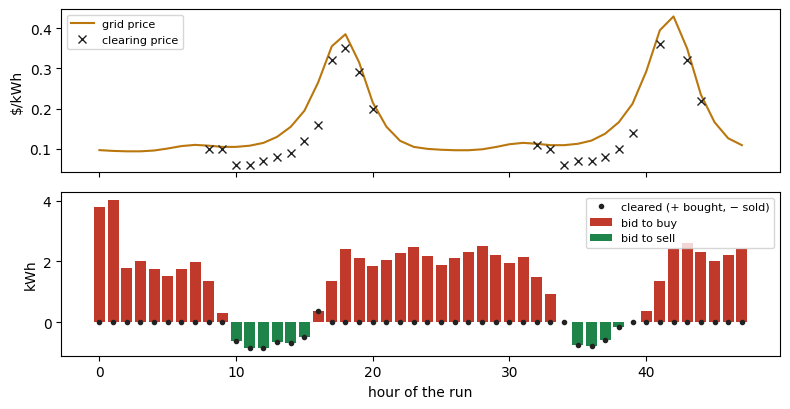

In [31]:
log = []
def recorder(step):
    m = step["market"]
    mine = step["bids"]["me"]
    log.append(dict(hour=m.timestep, grid=m.grid_import_price,
                    bid_buy=mine.clip(min=0).sum(), bid_sell=-mine.clip(max=0).sum(),
                    clearing=step["clearing"].price, got=step["clearing"].quantities["me"]))

run(Planner, recorder=recorder)
log = pd.DataFrame(log)

fig, ax = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True)
ax[0].plot(log.hour, log.grid, color="#b9770e", label="grid price")
ax[0].plot(log.hour, log.clearing, "x", color="#222", label="clearing price")
ax[0].set_ylabel("$/kWh"); ax[0].legend(fontsize=8)
ax[1].bar(log.hour, log.bid_buy, color="#c0392b", label="bid to buy")
ax[1].bar(log.hour, -log.bid_sell, color="#1e8449", label="bid to sell")
ax[1].plot(log.hour, log.got, ".", color="#222", label="cleared (+ bought, − sold)")
ax[1].set_ylabel("kWh"); ax[1].set_xlabel("hour of the run"); ax[1].legend(fontsize=8)
fig.tight_layout()

### What the runner does when your code goes wrong

`simulate()` runs every call through a guard that contains mistakes rather
than crashing the run:

| your code | what happens |
|---|---|
| `bid()` or `dispatch()` raises | the default agent stands in **for that hour**; counted in `failures`; the traceback is in the warnings |
| returns a malformed bid | repaired by `validate_bid` (part 3); noted in the warnings |
| `dispatch()` leaves a building out | that building gets an idle `Action()` |
| a call takes longer than `call_timeout_seconds` | an empty bid / idle actions that hour; counted in `timeouts` |
| all calls together exceed `run_budget_seconds` | disqualified for the rest of the run |

The **course market is stricter**: `altered_stock run` stops with an error
if your agent raised or timed out even once, so you cannot miss it. The
limits there are 5 s per call and 120 s for the whole run (README,
"Practical constraints"). Here is a bug that only fires in the evening:

In [32]:
class Buggy(Planner):
    def bid(self, obs, mkt):
        if mkt.hour == 18:
            raise ZeroDivisionError("my forecast divided by zero")
        return super().bid(obs, mkt)

result = run(Buggy)
me = next(p for p in result.participants if p.name == "me")
print("failures:", me.failures, "| timeouts:", me.timeouts)
print(result.ledger.warnings[0].splitlines()[0])

failures: 2 | timeouts: 0
me: bid raised, default agent substituted for that timestep


## 7. From notebook to submission

### The file

A submission is **one `.py` file** with three module-level names (README,
"Submission rules"):

| name | required | meaning |
|---|---|---|
| `BUILDINGS` | yes | the buildings you control, exactly your assignment |
| `AGENT` | yes | your `Agent` subclass (or an instance of it) |
| `NAME` | no | your participant name; defaults to the file name |

The runner imports every `*.py` in the submissions folder except files whose
name starts with `_`. Keep the module importable and cheap: no heavy work at
import time; load models and data in `reset()`.

Here is the step 3 planner as a file, on one storage-rich course house. We
write it to a scratch folder rather than into `submissions/`:

In [33]:
import tempfile

SOURCE = """
from annex96p2p import Action, Agent, Thermostat

NAME = "notebook_planner"
BUILDINGS = ["resstock-amy2018-2021-release-1-199613"]


class Planner(Agent):
    BUY_AT, SELL_AT = 0.80, 0.20
    TARGET_SOC = 0.5

    def reset(self):
        self.thermostat = Thermostat()
        self.plan = {}

    def battery_step(self, o):
        if not o.has_battery:
            return 0.0, 0.0
        gap = self.TARGET_SOC * o.battery_capacity_kwh - o.battery_soc_kwh
        kwh = max(-o.battery_max_power_kw, min(o.battery_max_power_kw, gap))
        return kwh / o.battery_max_power_kw, kwh

    def bid(self, obs, mkt):
        self.plan, net = {}, 0.0
        for name, o in obs.items():
            hvac = self.thermostat(o)
            battery, battery_kwh = self.battery_step(o)
            self.plan[name] = Action(hvac=hvac, battery=battery)
            net += o.passive_net_kwh + o.hp_draw_kwh(hvac) + battery_kwh
        b = mkt.new_bid()
        if net > 0:
            b.buy(self.BUY_AT * mkt.grid_import_price, net)
        elif net < 0:
            b.sell(self.SELL_AT * mkt.grid_import_price, -net)
        return b.array

    def dispatch(self, obs, mkt, result):
        return {name: self.plan.get(name, Action()) for name in obs}


AGENT = Planner
"""

scratch = Path(tempfile.mkdtemp(prefix="agent_notebook_"))
submissions = scratch / "submissions"
submissions.mkdir()
(submissions / "notebook_planner.py").write_text(SOURCE.lstrip(), encoding="utf-8")
print("written: <scratch>/submissions/notebook_planner.py")

written: <scratch>/submissions/notebook_planner.py


### Loading it the way the runner does

`registry.discover(folder, valid_buildings)` is what the runner calls. It
imports each file in isolation, checks `BUILDINGS` against the stock and
builds the agent. Running it yourself shows problems before a long run. Two
extra files show the checks: one whose name starts with `_`, and one that
claims a building that does not exist.

In [34]:
import pandas as pd
from annex96p2p.registry import discover

stock = ROOT / "generated/altered_stock/balanced/buildings.csv"
valid = (pd.read_csv(stock).building.tolist() if stock.exists() else
         ["resstock-amy2018-2021-release-1-199613", "resstock-amy2018-2021-release-1-112208"])

(submissions / "_draft.py").write_text("raise RuntimeError('never imported')\n")
(submissions / "typo.py").write_text(SOURCE.replace("199613", "199631").replace("notebook_planner", "typo"))

participants, report = discover(submissions, valid)
print(report.render())
print(participants)
(submissions / "_draft.py").unlink(); (submissions / "typo.py").unlink()

loaded submissions: notebook_planner
SKIPPED typo.py: claims no existing buildings
UNKNOWN BUILDING typo claims ['resstock-amy2018-2021-release-1-199631'], which do not exist
[Participant(notebook_planner, submission, 1 buildings)]


From the command line, `python -m annex96p2p check <file>` does a similar
load check for a single file.

### One run in the course market

The same folder goes straight into the course runner. Two days keep it short;
drop `--days` for the full month. This cell needs the course dataset
(`python -m annex96p2p.altered_stock build`, see the README) and is skipped
without it.

In [35]:
import subprocess

if not (ROOT / "generated/altered_stock/balanced/schema.json").exists():
    print("course dataset not built -- skipping (README, 'Getting set up')")
else:
    out = scratch / "results"
    command = [sys.executable, "-m", "annex96p2p.altered_stock", "run",
               "--configurations", "balanced", "--modes", "competitive",
               "--days", "2", "--submissions", str(submissions), "--out", str(out)]
    print(" ".join(command[1:]).replace(str(scratch), "<scratch>"))
    done = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
    if done.returncode != 0:
        raise RuntimeError(done.stdout[-1500:] + done.stderr[-3000:])
    print("finished; results in <scratch>/results")

    run_dir = out / "balanced" / "competitive"
    settled = pd.read_csv(run_dir / "settlements.csv")
    mine = settled[settled.participant == "notebook_planner"]
    print("\nfiles written:", sorted(p.name for p in run_dir.iterdir()))
    print("\nour two days: bought %.1f kWh, sold %.1f kWh, from the grid %.1f kWh, curtailed %.1f kWh, bill $%.2f"
          % (mine.p2p_kwh.clip(lower=0).sum(), abs(mine.p2p_kwh.clip(upper=0).sum()),
             mine.grid_import_kwh.sum(), mine.curtailed_kwh.sum(), mine.total_cost.sum()))

-m annex96p2p.altered_stock run --configurations balanced --modes competitive --days 2 --submissions <scratch>\submissions --out <scratch>\results


finished; results in <scratch>/results

files written: ['assignments.json', 'bids.csv', 'buildings_hourly.csv', 'daily.csv', 'hourly_audit.csv', 'leaderboard.csv', 'market.csv', 'offers.csv', 'participants.json', 'report.txt', 'settlements.csv', 'summary.json']

our two days: bought 6.3 kWh, sold 0.0 kWh, from the grid 507.8 kWh, curtailed 0.0 kWh, bill $108.06


The run folder holds everything the README's "Debugging your agent" section
describes. The ones you will use most:

- `settlements.csv`: the table from part 6, for every participant and hour;
- `bids.csv`: every nonzero entry of every bid vector;
- `hourly_audit.csv`: whether what was sold was physically backed;
- `python examples/hourly_trades.py --run <run folder>` turns the run into
  an interactive page with your bid heatmap.

To compare against the default agent on the same house, run once without
`--submissions` and compare the bills (README, "Is it any good?").

## Checklist

The mistakes below are all about plumbing, and all of them have appeared in
real submissions:

| symptom | cause | fix |
|---|---|---|
| grid imports in hours you bid | `dispatch()` does more than `bid()` bid for | plan in `bid()`, carry out the plan in `dispatch()` |
| curtailment after you bought | you bought more than you used | bid the planned net energy, not a guess |
| bid quantities far too large or small | `hvac`/`battery` treated as kWh | they are fractions of rated power; convert once |
| heat pump energy over-predicted | `abs(hvac) * hp_max_electric_kw` | use `o.hp_draw_kwh(hvac)` |
| shapes differ hour to hour | bid sized from a constant | size it from `mkt` (`empty_bid`, `new_bid`) |
| state leaks between runs | setup in `__init__` or at import | set up in `reset()` |
| run stops: unknown building / duplicate claim | `BUILDINGS` wrong | exactly your assignment; check with `discover` |
| run stops: agent raised / timed out | an exception or a slow call | test on the stub bench first; 5 s per call, 120 s per run |

Next: the README's "The API in full" for every field, and
[`agents/advanced/README.md`](../agents/advanced/README.md) for complete
agents built on this skeleton.